# Лабораторная работа № 3. Подготовка данных компьютерного зрения

**София Кавалеристова · вариант 9**

[Задание курса](https://github.com/ykvnkm/computer-vision-course/blob/main/labs/lab03/README.md). Обе части выполняются последовательно на CPU. В Kaggle для загрузки данных включите Internet.

## 0. Загрузка данных и зависимости

Ноутбук загружает официальный архив варианта 9. Если архив уже скачан, задайте путь к папке с ним в `DATA_SOURCE`. Граница trimap включена в маску, чтобы сохранить силуэт на переходе между животным и фоном.

In [1]:
import os

VARIANT = 9
DATA_SOURCE = os.environ.get('CV_DATA_SOURCE')  # запасной путь: папка с архивами variant_NN.zip

import sys
import inspect
import urllib.request
from pathlib import Path

assert isinstance(VARIANT, int) and 0 <= VARIANT <= 22, "Впишите свой номер варианта: целое число от 1 до 22"
if VARIANT == 0:
    print("ВНИМАНИЕ: вариант 00 демонстрационный, работа на нём не засчитывается")

if "google.colab" in sys.modules:
    ENV, DATA_ROOT = "colab", Path("/content/data")
elif Path("/kaggle/working").exists():
    ENV, DATA_ROOT = "kaggle", Path("/kaggle/working/data")
elif Path("../../data/get_data.py").exists():
    # Ноутбук открыт прямо из клона репозитория курса: данные кладём в его папку data/
    ENV, DATA_ROOT = "local", Path("../../data").resolve()
else:
    # Локально: ноутбук лежит в cv-2026-familiya/lab03/, данные кладём в cv-2026-familiya/data/.
    # Эта папка указана в .gitignore, в репозиторий она не попадёт.
    ENV, DATA_ROOT = "local", Path("..").resolve() / "data"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print("Среда:", ENV)

GET_DATA_URL = "https://raw.githubusercontent.com/ykvnkm/computer-vision-course/main/data/get_data.py"
course_copy = Path("../../data/get_data.py")
kaggle_copies = sorted(Path("/kaggle/input").glob("**/get_data.py")) if ENV == "kaggle" else []
if course_copy.exists():
    script_dir = course_copy.resolve().parent
elif kaggle_copies:
    # Kaggle с подключённым датасетом-зеркалом курса: интернет не нужен
    script_dir = kaggle_copies[0].parent
    print("get_data.py из подключённого датасета:", kaggle_copies[0])
else:
    script_dir = DATA_ROOT
    if not (script_dir / "get_data.py").exists():
        try:
            urllib.request.urlretrieve(GET_DATA_URL, script_dir / "get_data.py")
        except Exception as e:
            raise RuntimeError("Не удалось скачать get_data.py. В Kaggle включите Internet в Settings; "
                               "в остальных случаях проверьте подключение к сети.") from e
sys.path.insert(0, str(script_dir))
import get_data

# В Windows Path сортирует без учёта регистра. В манифесте курса
# пути отсортированы как в POSIX, поэтому используем тот же порядок.
if os.name == "nt":
    import hashlib

    def posix_content_digest(directory):
        root = Path(directory)
        files = [p for p in root.rglob("*") if p.is_file() and p.name != get_data.MARKER]
        files.sort(key=lambda p: p.relative_to(root).as_posix())
        lines = [f"{p.relative_to(root).as_posix()}\t{hashlib.sha256(p.read_bytes()).hexdigest()}\n"
                 for p in files]
        return hashlib.sha256("".join(lines).encode("utf-8")).hexdigest()

    get_data.content_digest = posix_content_digest

ensure_variant = get_data.ensure_variant

params = inspect.signature(ensure_variant).parameters
kwargs = {"dest": DATA_ROOT, "quiet": True} if "dest" in params else {}
if DATA_SOURCE and "source" in params:
    kwargs["source"] = DATA_SOURCE
DATA_DIR = Path(ensure_variant(VARIANT, **kwargs))
print("Данные:", DATA_DIR.name)
print(sorted(p.name for p in DATA_DIR.iterdir()))

Среда: local
Данные: variant_09
['.get_data.json', 'README.md', 'annotations', 'images', 'labels.csv', 'variant.json']


In [2]:
import importlib.metadata as metadata
import subprocess

os.environ.setdefault('NO_ALBUMENTATIONS_UPDATE', '1')

required = {"albumentations": "2.0.8", "ImageHash": "4.3.2", "scikit-learn": "1.7.2"}
install = []
for package, version in required.items():
    try:
        installed = metadata.version(package)
    except metadata.PackageNotFoundError:
        installed = None
    if installed != version:
        install.append(f"{package}=={version}")
if install:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *install])

import hashlib
import json
import xml.etree.ElementTree as ET

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import imagehash
import albumentations as A
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

IMG_DIR = DATA_DIR / "images"
TRIMAP_DIR = DATA_DIR / "annotations" / "trimaps"
XML_DIR = DATA_DIR / "annotations" / "xmls"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
SEED = 2026

labels = pd.read_csv(DATA_DIR / "labels.csv")
variant_info = json.loads((DATA_DIR / "variant.json").read_text(encoding="utf-8"))
CLASSES = list(variant_info["breeds"])          # индекс в списке = class_id из labels.csv
print(len(labels), "фото | классы:", dict(enumerate(CLASSES)))
print("OpenCV", cv2.__version__, "| albumentations", A.__version__, "| imagehash", imagehash.__version__)

797 фото | классы: {0: 'Persian', 1: 'Sphynx', 2: 'american_bulldog', 3: 'staffordshire_bull_terrier'}
OpenCV 4.12.0 | albumentations 2.0.8 | imagehash 4.3.2


### Общие функции

Готовый код, менять не нужно.

- `read_xml(filename)` читает Pascal VOC XML фото: размер кадра из `<size>` и список объектов, у каждого `name`, флаги и рамка `bbox` = `[xmin, ymin, xmax, ymax]` в пикселях со счётом от 1. Если XML нет, возвращает `None`.
- `load_rgb(filename)` читает фото в исходном размере через `.convert("RGB")`. В этой лабе фото не уменьшаем: рамки и маски должны совпадать с исходными пикселями.
- `load_trimap(filename)` читает trimap: 1 = животное, 2 = фон, 3 = граница.
- `draw_boxes(rgb, boxes, color)` рисует рамки `[xmin, ymin, xmax, ymax]`, `show_grid` рисует картинки сеткой и сохраняет PNG.

In [3]:
def read_xml(filename):
    """{"width", "height", "objects": [{"name", "truncated", "occluded", "difficult", "bbox"}]} или None."""
    path = XML_DIR / (Path(filename).stem + ".xml")
    if not path.exists():
        return None
    root = ET.parse(path).getroot()
    size = root.find("size")
    objects = []
    for obj in root.findall("object"):
        bb = obj.find("bndbox")
        objects.append({
            "name": obj.findtext("name"),
            "truncated": int(obj.findtext("truncated", "0")),
            "occluded": int(obj.findtext("occluded", "0")),
            "difficult": int(obj.findtext("difficult", "0")),
            "bbox": [int(float(bb.findtext(k))) for k in ("xmin", "ymin", "xmax", "ymax")],
        })
    return {"width": int(size.findtext("width")), "height": int(size.findtext("height")), "objects": objects}


def load_rgb(filename):
    with Image.open(IMG_DIR / filename) as im:
        return np.asarray(im.convert("RGB"))


def load_trimap(filename):
    with Image.open(TRIMAP_DIR / (Path(filename).stem + ".png")) as im:
        return np.asarray(im)


def draw_boxes(rgb, boxes, color=(255, 196, 0), thickness=None):
    out = np.ascontiguousarray(rgb.copy())
    th = thickness or max(2, round(max(rgb.shape[:2]) / 250))
    for b in boxes:
        x0, y0, x1, y1 = [int(round(v)) for v in b[:4]]
        cv2.rectangle(out, (x0, y0), (x1, y1), color, th)
    return out


def draw_mask_contour(rgb, mask, color=(46, 123, 255)):
    out = np.ascontiguousarray(rgb.copy())
    cs, _ = cv2.findContours(np.asarray(mask, np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    cv2.drawContours(out, cs, -1, color, max(2, round(max(rgb.shape[:2]) / 300)))
    return out


def show_grid(images, titles=None, ncols=4, path=None, size=3.0):
    nrows = (len(images) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i, img in enumerate(images):
        ax = axes.ravel()[i]
        img = np.asarray(img)
        ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
        if titles is not None:
            ax.set_title(titles[i], fontsize=8)
    plt.tight_layout()
    if path is not None:
        plt.savefig(path, dpi=100)
    plt.show()
    plt.close(fig)


first = labels["filename"].iloc[0]
print(first, load_rgb(first).shape, read_xml(first))

american_bulldog_2.jpg (333, 500, 3) None


# Часть 1. Разметка, форматы, дубликаты

Делается после лекции 4. Результат части: таблица проверки разметки, разметка в форматах COCO и YOLO с проверкой перевода, список пар-дубликатов с вашей отметкой и графики распределений. В часть 2 переходят отмеченные пары: из них соберутся группы для разбиения.

## 1.1 Проверка разметки

Допишите `audit_one`: словарь проверок для одного фото. Размер фото, наличие XML и число рамок готовая функция `base_info` уже считает. Готовая ячейка ниже пройдёт по всем фото, сохранит `results/audit.csv` и покажет фото, где хоть одна проверка не прошла.

| Поле | Что это |
|---|---|
| `format` | формат по первым байтам файла: `jpeg` (`FF D8`), `png` (`89 50 4E 47`), `gif` (`47 49 46`), иначе `other` |
| `mode` | режим Pillow: `RGB`, `L`, `RGBA`, `P` |
| `xml_size_ok` | размер в XML совпадает с фото (`True`, если XML нет) |
| `boxes_inside` | все рамки внутри кадра: `1 <= xmin < xmax <= width`, то же по y |
| `trimap_size_ok` | trimap того же размера, что фото |
| `trimap_empty` | в trimap нет ни одного пикселя 1 и 3 |
| `box_on_animal` | для первой рамки: доля её пикселей, где trimap не 2 (`NaN`, если рамки нет или маска пустая) |
| `box_area_frac` | площадь первой рамки / площадь кадра (`NaN`, если рамки нет) |

In [4]:
def image_boxes(xml):
    return [o["bbox"] for o in xml["objects"]] if xml else []


def audit_one(filename):
    path = IMG_DIR / filename
    with path.open("rb") as stream:
        sig = stream.read(8)
    signatures = {b"\xff\xd8\xff": "jpeg", b"\x89PNG\r\n\x1a\n": "png",
                  b"GIF87a": "gif", b"GIF89a": "gif", b"BM": "bmp",
                  b"II*\x00": "tiff", b"MM\x00*": "tiff"}
    fmt = next((name for prefix, name in signatures.items() if sig.startswith(prefix)), "unknown")
    with Image.open(path) as im:
        w, h = im.size
        mode = im.mode
    xml = read_xml(filename)
    boxes = image_boxes(xml)
    tri = load_trimap(filename)
    mask_size_ok = tri.shape == (h, w)
    inside = all(1 <= x0 <= x1 <= w and 1 <= y0 <= y1 <= h for x0, y0, x1, y1 in boxes)
    coverage = []
    areas = []
    for x0, y0, x1, y1 in boxes:
        if 1 <= x0 <= x1 <= w and 1 <= y0 <= y1 <= h:
            areas.append((x1-x0+1) * (y1-y0+1) / (w*h))
            if mask_size_ok:
                coverage.append(float(np.isin(tri[y0-1:y1, x0-1:x1], [1, 3]).mean()))
    return {
        "filename": filename, "width": w, "height": h, "has_xml": xml is not None,
        "n_boxes": len(boxes), "format": fmt, "mode": mode,
        "xml_size_ok": (xml["width"], xml["height"]) == (w, h) if xml else None,
        "boxes_inside": inside if boxes else None, "trimap_size_ok": mask_size_ok,
        "trimap_empty": not np.isin(tri, [1, 3]).any(),
        "box_on_animal": min(coverage, default=np.nan),
        "box_area_frac": min(areas, default=np.nan),
    }

In [5]:
CHECKS = ["format", "mode", "xml_size_ok", "boxes_inside", "trimap_size_ok", "trimap_empty", "box_on_animal", "box_area_frac"]
audit = pd.DataFrame([audit_one(fn) for fn in labels["filename"]]).merge(labels, on="filename")
audit = audit.reindex(columns=list(dict.fromkeys(list(audit.columns) + CHECKS)))
audit.to_csv(RESULTS / "audit.csv", index=False, float_format="%.4f")
flag = lambda col, bad: audit[col].map(lambda v: v == bad if isinstance(v, (bool, np.bool_)) else False)
problems = audit[(audit["format"].notna() & (audit["format"] != "jpeg")) | (audit["mode"].notna() & (audit["mode"] != "RGB"))
                 | (audit["n_boxes"] > 1) | flag("xml_size_ok", False) | flag("boxes_inside", False)
                 | flag("trimap_size_ok", False) | flag("trimap_empty", True) | (audit["box_on_animal"] < 0.5)]
print(len(audit), "фото,", len(problems), "с замечаниями")
print(problems[["filename", "format", "mode", "n_boxes", "trimap_empty", "box_on_animal"]].to_string())
issue_counts = {
    "non_jpeg": int(audit["format"].ne("jpeg").sum()),
    "non_rgb": int(audit["mode"].ne("RGB").sum()),
    "multiple_boxes": int(audit["n_boxes"].gt(1).sum()),
    "xml_size": int(flag("xml_size_ok", False).sum()),
    "boxes_outside": int(flag("boxes_inside", False).sum()),
    "trimap_size": int(flag("trimap_size_ok", False).sum()),
    "trimap_empty": int(flag("trimap_empty", True).sum()),
    "box_overlap_low": int(audit["box_on_animal"].lt(0.5).sum()),
}
print(pd.Series(issue_counts).to_string())
assert len(audit) == 797 and audit["filename"].is_unique
assert issue_counts["boxes_outside"] == issue_counts["trimap_size"] == 0

797 фото, 3 с замечаниями
                              filename format mode  n_boxes  trimap_empty  box_on_animal
388                    Persian_259.jpg   jpeg  RGB        0          True            NaN
606   staffordshire_bull_terrier_2.jpg   jpeg    L        0          True            NaN
626  staffordshire_bull_terrier_22.jpg   jpeg    L        0          True            NaN
non_jpeg           0
non_rgb            2
multiple_boxes     0
xml_size           0
boxes_outside      0
trimap_size        0
trimap_empty       3
box_overlap_low    0


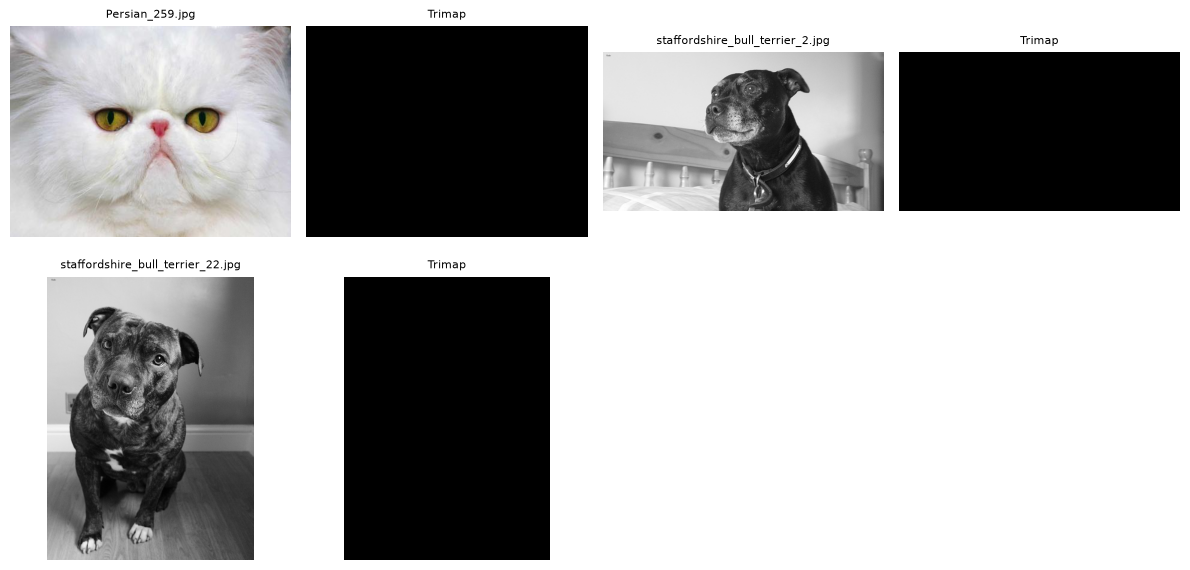

In [6]:
examples = problems.sort_values("box_on_animal", na_position="last").head(4)
panels, titles = [], []
for row in examples.itertuples():
    fn = row.filename
    boxes = [[v - 1 for v in box] for box in image_boxes(read_xml(fn))]
    panels.extend([draw_boxes(load_rgb(fn), boxes), load_trimap(fn) * 80])
    titles.extend([fn, "Trimap"])
if panels:
    show_grid(panels, titles, ncols=4)

## 1.2 COCO и YOLO

Разметка переводится в два формата, каждый под свою задачу курса:

- **COCO** для сегментации (лекция 10, лаба 6 по желанию): объект — животное. Полигон `segmentation` получаем из маски trimap через `cv2.findContours`, `bbox` — рамка этой маски (`cv2.boundingRect`) в формате `[x, y, w, h]` со счётом от 0. Рамка головы сюда не идёт: в COCO рамка и маска должны описывать один объект.
- **YOLO** для детекции голов (лаба 5): по txt-файлу на фото с XML, строка `class cx cy w h` в долях кадра на каждую рамку головы.

Класс берите из `labels.csv`, а не из XML: в XML записан вид, `cat` или `dog`.

Сначала решите, что делать с границей trimap (значение 3): отнести к животному или к фону. Впишите решение в `BORDER_AS` и объясните его в отчёте.

In [7]:
BORDER_AS = "animal"


def animal_mask(tri):
    return ((tri == 1) | ((tri == 3) & (BORDER_AS == "animal"))).astype(np.uint8)


def voc_to_coco(b):
    x0, y0, x1, y1 = b
    return [x0 - 1, y0 - 1, x1 - x0 + 1, y1 - y0 + 1]


def coco_to_yolo(bbox, W, H):
    x, y, w, h = bbox
    return ((x + w / 2) / W, (y + h / 2) / H, w / W, h / H)


def yolo_to_voc(cx, cy, w, h, W, H):
    x, y = (cx - w / 2) * W, (cy - h / 2) * H
    return [x + 1, y + 1, x + w * W, y + h * H]


def mask_to_polygons(mask, eps=1.0):
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    polygons = []
    for contour in contours:
        points = cv2.approxPolyDP(contour, eps, True)
        if len(points) >= 3 and cv2.contourArea(points) > 0:
            polygons.append(points.reshape(-1).tolist())
    return polygons


def polygons_to_mask(polygons, shape):
    """Обратно: заливка полигонов cv2.fillPoly в маску uint8 размером shape."""
    m = np.zeros(shape, np.uint8)
    pts = [np.array(p, np.int32).reshape(-1, 2) for p in polygons]
    if pts:
        cv2.fillPoly(m, pts, 1)
    return m

In [8]:
# Готовая сборка COCO и YOLO из ваших функций.
coco = {"images": [], "annotations": [],
        "categories": [{"id": i, "name": name} for i, name in enumerate(CLASSES)]}
YOLO_DIR = RESULTS / "yolo"
(YOLO_DIR / "labels").mkdir(parents=True, exist_ok=True)
for old in (YOLO_DIR / "labels").glob("*.txt"):
    old.unlink()

for image_id, r in enumerate(audit.itertuples(), start=1):
    coco["images"].append({"id": image_id, "file_name": r.filename, "width": int(r.width), "height": int(r.height)})
    mask = animal_mask(load_trimap(r.filename))
    polys = mask_to_polygons(mask)
    if polys:
        points = np.concatenate([np.asarray(p, np.int32).reshape(-1, 2) for p in polys])
        x, y, w, h = cv2.boundingRect(points)
        coco["annotations"].append({"id": len(coco["annotations"]) + 1, "image_id": image_id,
                                    "category_id": int(r.class_id), "segmentation": polys,
                                    "bbox": [x, y, w, h], "area": int(polygons_to_mask(polys, mask.shape).sum()), "iscrowd": 0})
    xml = read_xml(r.filename)
    if xml:
        lines = [f"{r.class_id} " + " ".join(f"{v:.6f}" for v in coco_to_yolo(voc_to_coco(o["bbox"]), r.width, r.height))
                 for o in xml["objects"]]
        (YOLO_DIR / "labels" / (Path(r.filename).stem + ".txt")).write_text("\n".join(lines) + "\n")

(RESULTS / "coco.json").write_text(json.dumps(coco))
(YOLO_DIR / "data.yaml").write_text(
    "# пути к фото задаются в лабе 5\nnames:\n" + "".join(f"  {i}: {n}\n" for i, n in enumerate(CLASSES)), encoding="utf-8", newline="\n")
print("COCO:", len(coco["images"]), "фото,", len(coco["annotations"]), "объектов | YOLO:",
      len(list((YOLO_DIR / "labels").glob("*.txt"))), "файлов")

COCO: 797 фото, 794 объектов | YOLO: 404 файлов


## 1.3 Проверка перевода

Две проверки, обе готовые. Первая читает рамки обратно из файлов YOLO, переводит их в VOC вашей `yolo_to_voc` и сравнивает с XML: расхождение должно быть меньше пикселя. Рамки из YOLO рисуются на 6 случайных фото красным поверх исходных зелёных. Вторая восстанавливает каждую маску из полигона COCO и считает IoU с исходной маской.

рамки VOC → YOLO → VOC: максимальное расхождение 0.000300 px
маска → полигон → маска: IoU медиана 0.9963, минимум 0.0000
Минимум по непустым маскам: 0.7758 (Persian_273.jpg)


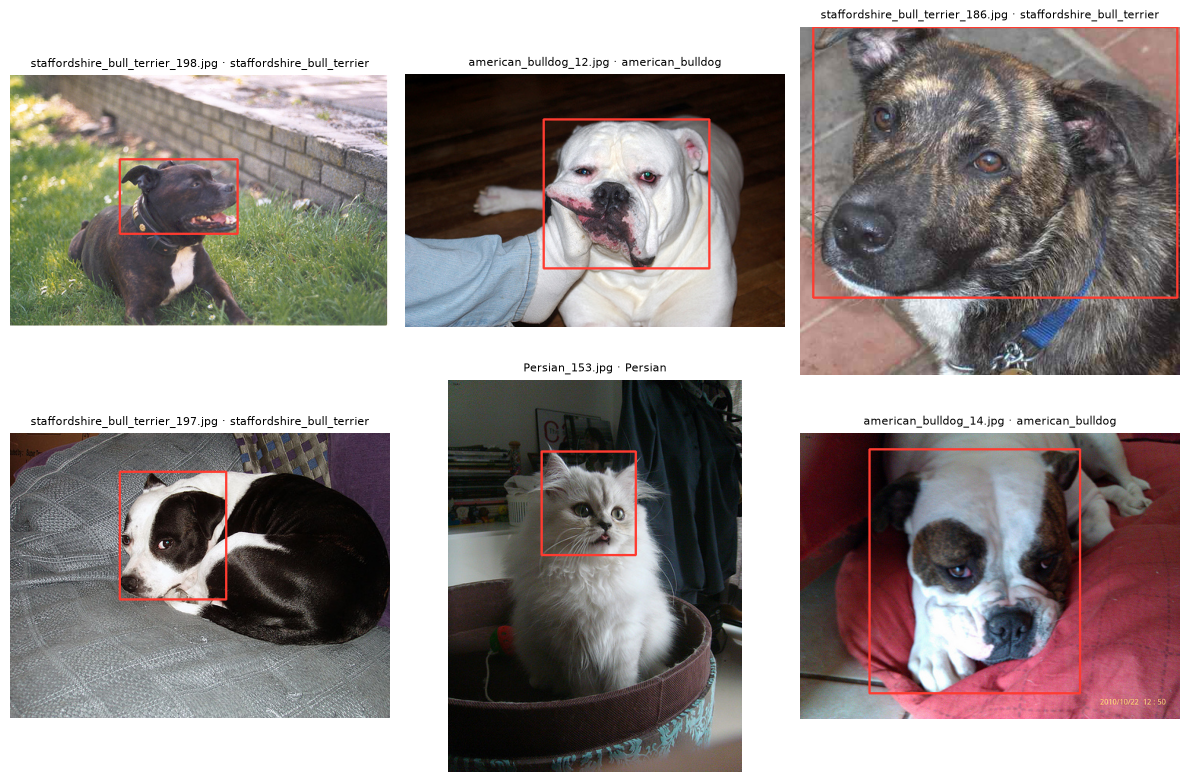

In [9]:
diffs, panels, titles = [], [], []
with_xml = audit[audit["has_xml"]]
for r in with_xml.itertuples():
    xml = read_xml(r.filename)
    txt = (YOLO_DIR / "labels" / (Path(r.filename).stem + ".txt")).read_text().split("\n")
    lines = [t for t in txt if t]
    assert len(lines) == len(xml["objects"])
    for o, line in zip(xml["objects"], lines):
        cls, cx, cy, w, h = line.split()
        assert int(cls) == r.class_id
        back = yolo_to_voc(float(cx), float(cy), float(w), float(h), r.width, r.height)
        diffs.append(max(abs(a - b) for a, b in zip(back, o["bbox"])))
for r in with_xml.sample(min(6, len(with_xml)), random_state=VARIANT).itertuples():
    xml = read_xml(r.filename); rgb = load_rgb(r.filename)
    txt = [t for t in (YOLO_DIR / "labels" / (Path(r.filename).stem + ".txt")).read_text().split("\n") if t]
    yolo_boxes = [yolo_to_voc(*map(float, t.split()[1:]), r.width, r.height) for t in txt]
    img = draw_boxes(rgb, [[v - 1 for v in box] for box in yolo_boxes], (255, 59, 48))
    panels.append(img); titles.append(f"{r.filename} · {CLASSES[int(txt[0].split()[0])] if txt else '-'}")

ious, iou_files, ious_nonempty = [], [], []
ann_by_image = {a["image_id"]: a for a in coco["annotations"]}
for img_info in coco["images"]:
    a = ann_by_image.get(img_info["id"])
    m0 = animal_mask(load_trimap(img_info["file_name"]))
    m1 = polygons_to_mask(a["segmentation"] if a else [], m0.shape)
    iou_files.append(img_info['file_name'])
    # Для двух пустых масок принимаем IoU = 0 по формуле стартового ноутбука.
    iou = (m0 & m1).sum() / max((m0 | m1).sum(), 1)
    ious.append(iou)
    if m0.any():
        ious_nonempty.append((iou, img_info["file_name"]))
print(f"рамки VOC → YOLO → VOC: максимальное расхождение {max(diffs) if diffs else float('nan'):.6f} px")
print(f"маска → полигон → маска: IoU медиана {np.median(ious) if ious else float('nan'):.4f}, минимум {min(ious) if ious else float('nan'):.4f}")
assert max(diffs) < 0.001 and len(ious) == len(audit)
worst_iou, worst_file = min(ious_nonempty)
print(f"Минимум по непустым маскам: {worst_iou:.4f} ({worst_file})")
show_grid(panels, titles, ncols=3, path=RESULTS / "format_check.png", size=4)

## 1.4 Дубликаты

Ищем копии одного фото и серии снимков одного животного. Как в лекции 4: MD5 ловит побайтовые копии, перцептивные хэши упорядочивают остальные пары от похожих к непохожим, а решение «дубликат или нет» принимаете вы, глядя на картинки.

Допишите `image_hashes`: MD5 файла, `imagehash.phash` и `imagehash.dhash` фото, а также phash и dhash отражённого фото (`ImageOps.mirror`), чтобы ловить отражения. Готовые ячейки посчитают расстояния для всех пар, сохранят первые 30 пар в `results/dup_candidates.png` и подготовят словарь для ваших отметок.

In [10]:
def image_hashes(filename):
    path = IMG_DIR / filename
    with Image.open(path) as source:
        image = source.convert("RGB")
    mirrored = ImageOps.mirror(image)
    return {"md5": hashlib.md5(path.read_bytes()).hexdigest(),
            "phash": imagehash.phash(image), "dhash": imagehash.dhash(image),
            "phash_m": imagehash.phash(mirrored), "dhash_m": imagehash.dhash(mirrored)}

In [11]:
files = labels["filename"].tolist()
H = [image_hashes(fn) for fn in files]
N = len(files)
pairs = pd.DataFrame(columns=["a", "b", "dist", "exact"])
if H and H[0]:
    bits = lambda key: np.array([h[key].hash.ravel() for h in H])        # N × 64 бита
    P, D, Pm, Dm = bits("phash"), bits("dhash"), bits("phash_m"), bits("dhash_m")
    ham = lambda X, Y: (X[:, None, :] != Y[None, :, :]).sum(-1)          # попарное расстояние Хэмминга
    direct = ham(P, P) + ham(D, D)
    mirrored = ham(Pm, P) + ham(Dm, D)
    dist = np.minimum(direct, np.minimum(mirrored, mirrored.T))
    md5 = np.array([h["md5"] for h in H])
    i, j = np.triu_indices(N, k=1)
    pairs = pd.DataFrame({"a": np.array(files)[i], "b": np.array(files)[j], "dist": dist[i, j],
                          "mirror": (mirrored[i, j] < direct[i, j]) | (mirrored[j, i] < direct[i, j]),
                          "exact": md5[i] == md5[j]})
    pairs.loc[pairs["exact"], "dist"] = 0
    pairs = pairs.sort_values(["dist", "a", "b"]).reset_index(drop=True)
print(N, "фото,", len(pairs), "пар | побайтовых копий:", int(pairs["exact"].sum()) if len(pairs) else 0)
pairs.head(10)

797 фото, 317206 пар | побайтовых копий: 1


,a,b,dist,mirror,exact
0,Persian_54.jpg,Persian_218.jpg,0,False,False
1,Sphynx_204.jpg,Sphynx_265.jpg,0,False,False
2,american_bulldog_15.jpg,american_bulldog_162.jpg,0,False,True
3,american_bulldog_215.jpg,american_bulldog_216.jpg,0,False,False
4,staffordshire_bull_terrier_145.jpg,staffordshire_bull_terrier_178.jpg,0,True,False
5,staffordshire_bull_terrier_143.jpg,staffordshire_bull_terrier_155.jpg,12,False,False
6,staffordshire_bull_terrier_169.jpg,staffordshire_bull_terrier_171.jpg,16,False,False
7,Sphynx_112.jpg,Sphynx_264.jpg,18,False,False
8,Persian_7.jpg,Persian_184.jpg,26,False,False
9,staffordshire_bull_terrier_165.jpg,staffordshire_bull_terrier_169.jpg,27,False,False


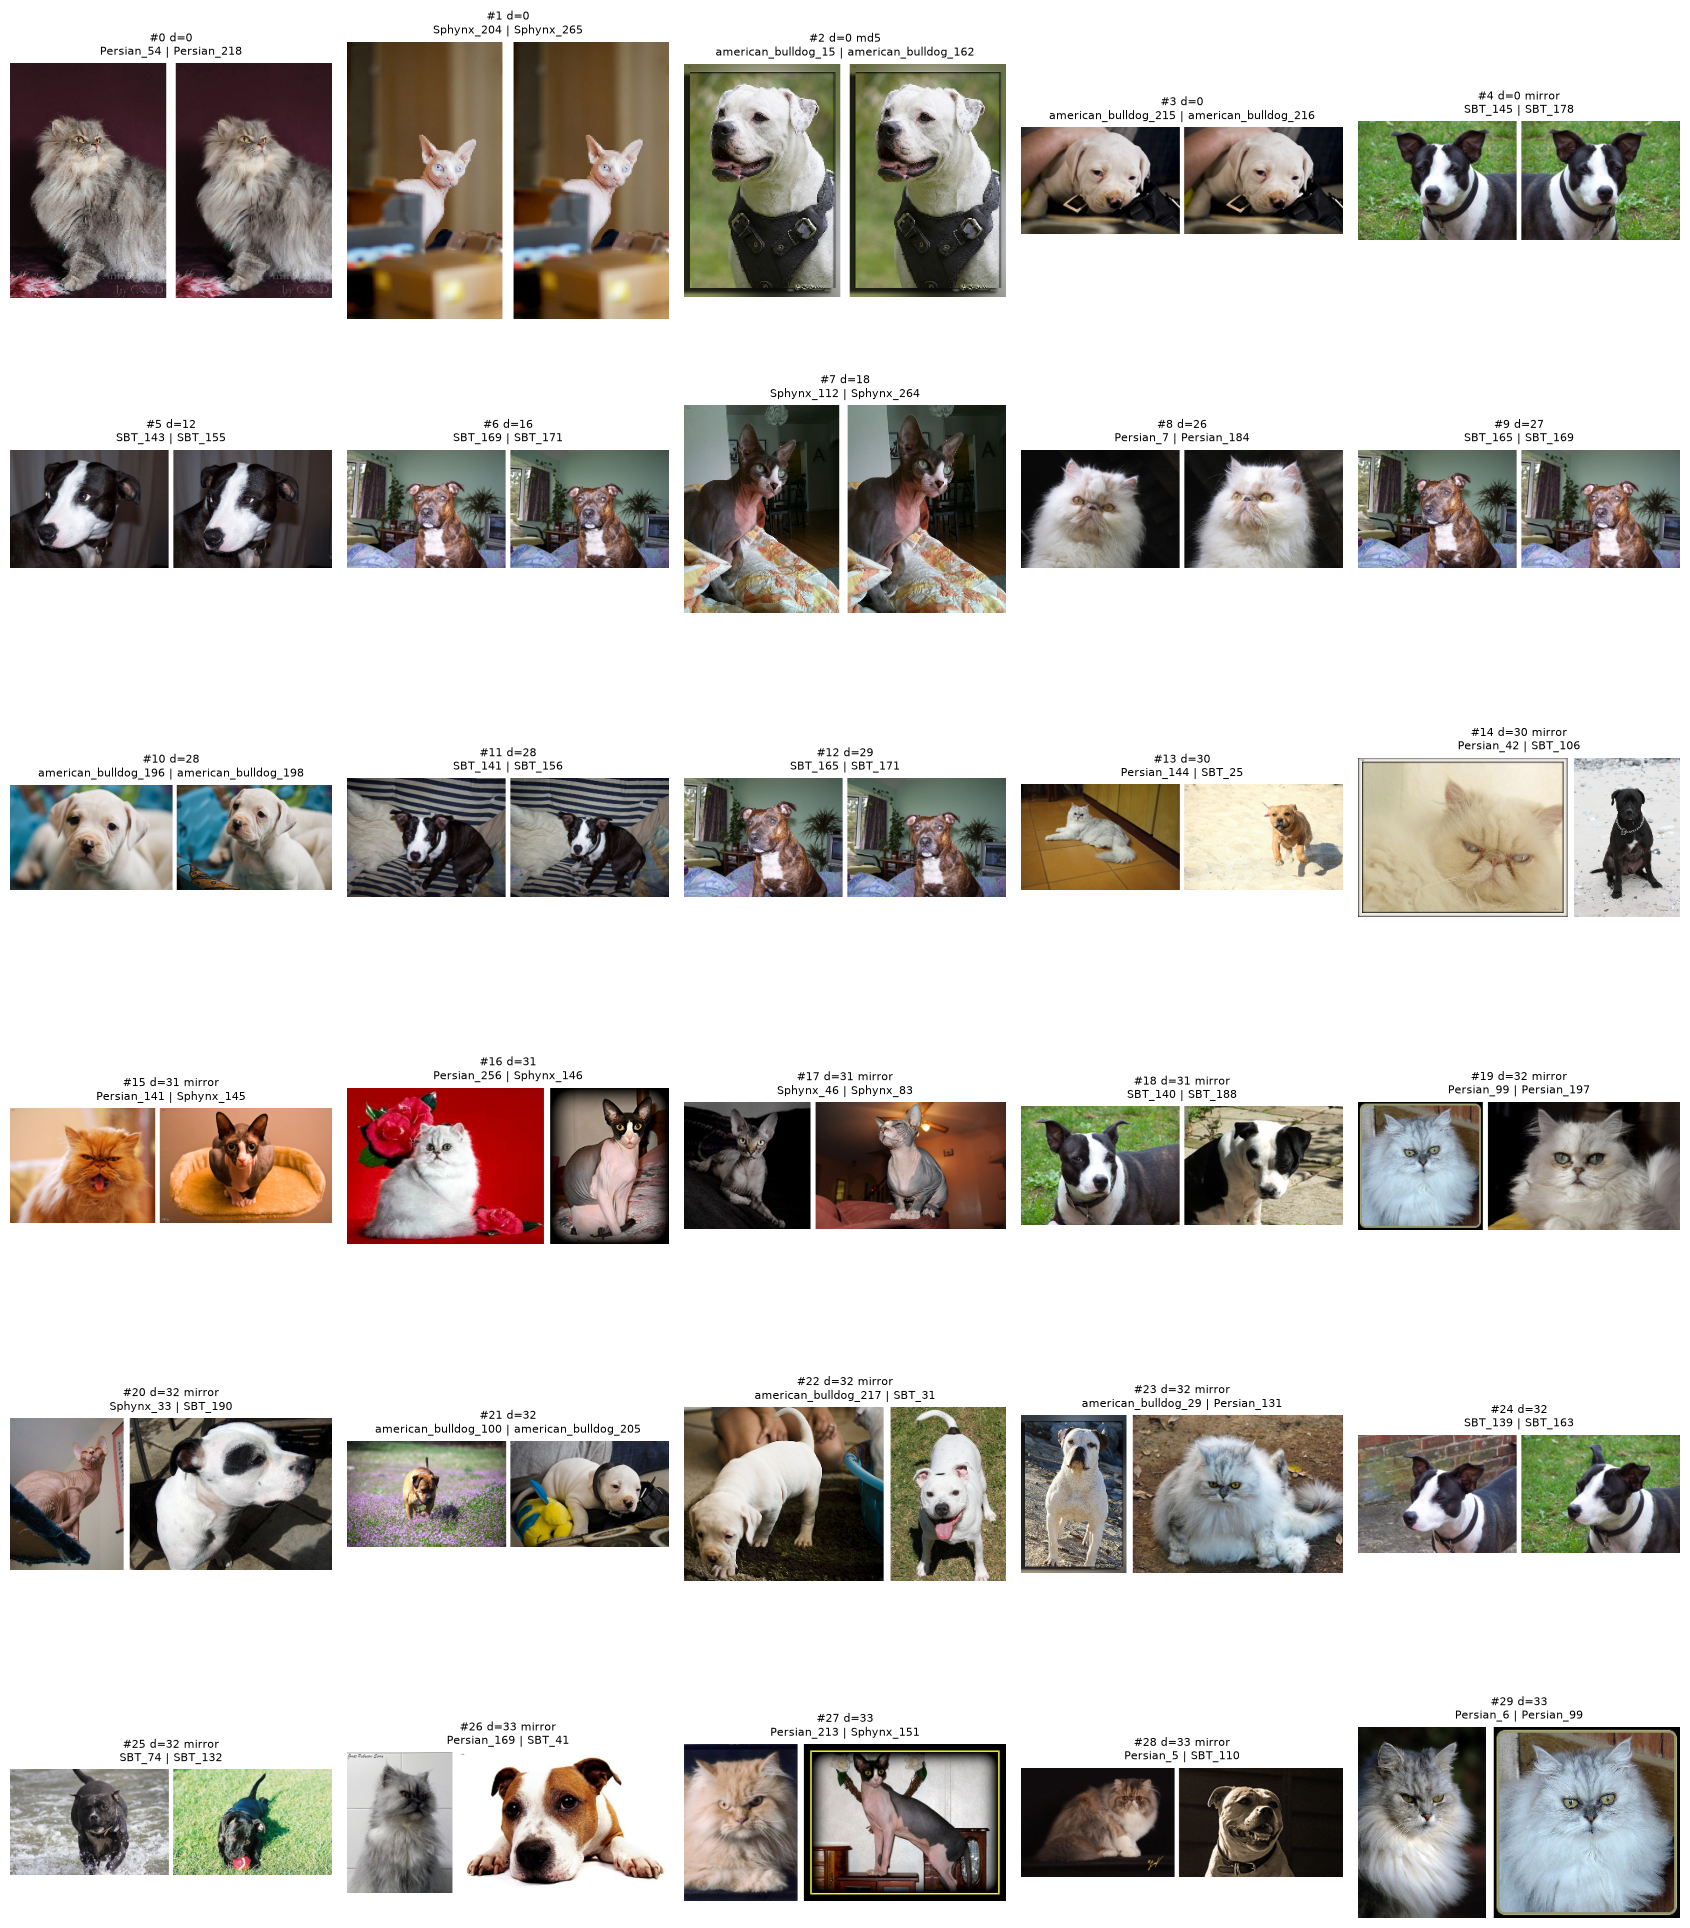

,rank,a,b,dist,mirror,exact
0,0,Persian_54.jpg,Persian_218.jpg,0,False,False
1,1,Sphynx_204.jpg,Sphynx_265.jpg,0,False,False
2,2,american_bulldog_15.jpg,american_bulldog_162.jpg,0,False,True
3,3,american_bulldog_215.jpg,american_bulldog_216.jpg,0,False,False
4,4,staffordshire_bull_terrier_145.jpg,staffordshire_bull_terrier_178.jpg,0,True,False
5,5,staffordshire_bull_terrier_143.jpg,staffordshire_bull_terrier_155.jpg,12,False,False
6,6,staffordshire_bull_terrier_169.jpg,staffordshire_bull_terrier_171.jpg,16,False,False
7,7,Sphynx_112.jpg,Sphynx_264.jpg,18,False,False
8,8,Persian_7.jpg,Persian_184.jpg,26,False,False
9,9,staffordshire_bull_terrier_165.jpg,staffordshire_bull_terrier_169.jpg,27,False,False


In [12]:
TOP = pairs.head(30).copy()
TOP.insert(0, "rank", range(len(TOP)))
panels, titles = [], []
for r in TOP.itertuples():
    a, b = load_rgb(r.a), load_rgb(r.b)
    h = 200
    a = cv2.resize(a, (round(a.shape[1] * h / a.shape[0]), h)); b = cv2.resize(b, (round(b.shape[1] * h / b.shape[0]), h))
    panels.append(np.hstack([a, np.full((h, 8, 3), 255, np.uint8), b]))
    titles.append(f"#{r.rank} d={r.dist}{' md5' if r.exact else ''}{' mirror' if r.mirror else ''}\n{Path(r.a).stem.replace('staffordshire_bull_terrier', 'SBT')} | {Path(r.b).stem.replace('staffordshire_bull_terrier', 'SBT')}")
if panels:
    show_grid(panels, titles, ncols=5, path=RESULTS / "dup_candidates.png", size=3.4)
display(TOP)

In [13]:
# Вердикты по визуальной сверке листа из 30 пар. Имена защищают от сдвига рангов.
VERDICT = {
    ("Persian_54.jpg", "Persian_218.jpg"): "same",
    ("Sphynx_204.jpg", "Sphynx_265.jpg"): "same",
    ("american_bulldog_15.jpg", "american_bulldog_162.jpg"): "same",
    ("american_bulldog_215.jpg", "american_bulldog_216.jpg"): "same",
    ("staffordshire_bull_terrier_145.jpg", "staffordshire_bull_terrier_178.jpg"): "same",
    ("staffordshire_bull_terrier_143.jpg", "staffordshire_bull_terrier_155.jpg"): "series",
    ("staffordshire_bull_terrier_169.jpg", "staffordshire_bull_terrier_171.jpg"): "series",
    ("Sphynx_112.jpg", "Sphynx_264.jpg"): "same",
    ("Persian_7.jpg", "Persian_184.jpg"): "series",
    ("staffordshire_bull_terrier_165.jpg", "staffordshire_bull_terrier_169.jpg"): "series",
    ("american_bulldog_196.jpg", "american_bulldog_198.jpg"): "series",
    ("staffordshire_bull_terrier_141.jpg", "staffordshire_bull_terrier_156.jpg"): "series",
    ("staffordshire_bull_terrier_165.jpg", "staffordshire_bull_terrier_171.jpg"): "series",
    ("Persian_144.jpg", "staffordshire_bull_terrier_25.jpg"): "different",
    ("Persian_42.jpg", "staffordshire_bull_terrier_106.jpg"): "different",
    ("Persian_141.jpg", "Sphynx_145.jpg"): "different",
    ("Persian_256.jpg", "Sphynx_146.jpg"): "different",
    ("Sphynx_46.jpg", "Sphynx_83.jpg"): "different",
    ("staffordshire_bull_terrier_140.jpg", "staffordshire_bull_terrier_188.jpg"): "different",
    ("Persian_99.jpg", "Persian_197.jpg"): "different",
    ("Sphynx_33.jpg", "staffordshire_bull_terrier_190.jpg"): "different",
    ("american_bulldog_100.jpg", "american_bulldog_205.jpg"): "different",
    ("american_bulldog_217.jpg", "staffordshire_bull_terrier_31.jpg"): "different",
    ("american_bulldog_29.jpg", "Persian_131.jpg"): "different",
    ("staffordshire_bull_terrier_139.jpg", "staffordshire_bull_terrier_163.jpg"): "series",
    ("staffordshire_bull_terrier_74.jpg", "staffordshire_bull_terrier_132.jpg"): "different",
    ("Persian_169.jpg", "staffordshire_bull_terrier_41.jpg"): "different",
    ("Persian_213.jpg", "Sphynx_151.jpg"): "different",
    ("Persian_5.jpg", "staffordshire_bull_terrier_110.jpg"): "different",
    ("Persian_6.jpg", "Persian_99.jpg"): "different",
}

In [14]:
dup = TOP.copy()
dup["verdict"] = [VERDICT[(r.a, r.b)] for r in TOP.itertuples()]
extra = pairs.loc[pairs["exact"] & (pairs.index >= len(TOP))].assign(rank=-1, verdict="same")
dup = pd.concat([dup, extra[dup.columns]], ignore_index=True)
dup.to_csv(RESULTS / "dup_pairs.csv", index=False)
print(dup["verdict"].value_counts().to_string())

verdict
different    16
series        8
same          6


## 1.5 Распределения

Один рисунок `results/distribution.png` из трёх графиков: число фото по породам, число фото с рамкой головы по породам, гистограмма `box_area_frac` (площадь рамки в долях кадра) с вертикальной линией медианы. Всё нужное есть в таблице `audit`.

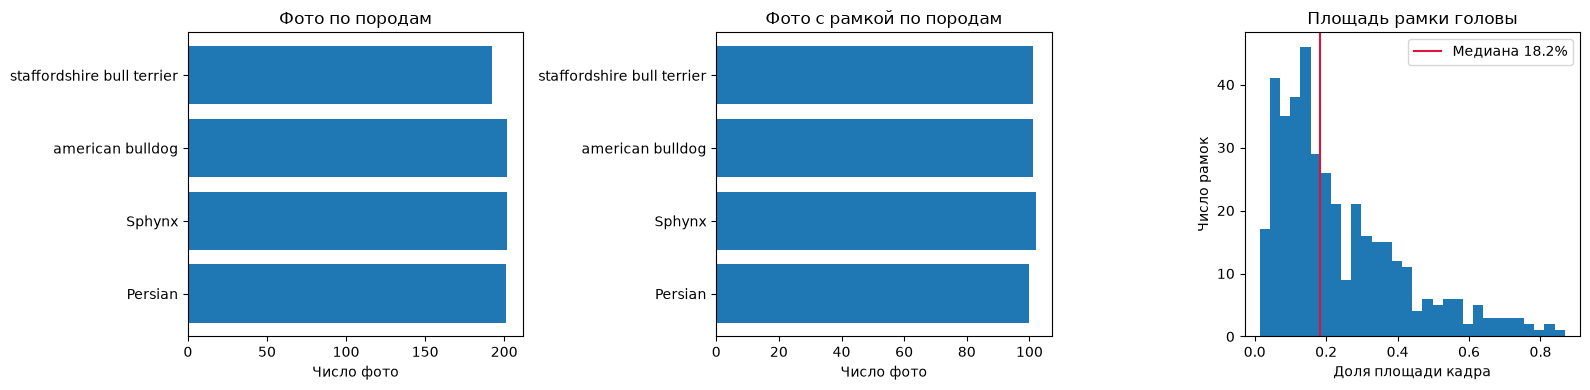

Рамок: 404 | медианная площадь: 18.17% | площадь меньше 5%: 5.94% | минимальная сторона: 42 px


In [15]:
box_records = [
    (r.filename, r.width, r.height, box)
    for r in audit[audit["n_boxes"] > 0].itertuples()
    for box in image_boxes(read_xml(r.filename))
]
box_sizes = np.array([voc_to_coco(box)[2:] for fn, w, h, box in box_records])
box_areas = box_sizes.prod(axis=1) / np.array([w*h for fn, w, h, box in box_records])
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
breed_counts = audit.groupby("breed").size()
box_counts = audit[audit["n_boxes"] > 0].groupby("breed").size().reindex(breed_counts.index, fill_value=0)
for ax, values, title in zip(axes[:2], [breed_counts, box_counts], ["Фото по породам", "Фото с рамкой по породам"]):
    ax.barh([name.replace("_", " ") for name in values.index], values)
    ax.set_title(title)
    ax.set_xlabel("Число фото")
median_area = float(np.median(box_areas))
axes[2].hist(box_areas, bins=30)
axes[2].axvline(median_area, color="crimson", label=f"Медиана {median_area:.1%}")
axes[2].set(xlabel="Доля площади кадра", ylabel="Число рамок", title="Площадь рамки головы")
axes[2].legend()
fig.tight_layout()
fig.savefig(RESULTS / "distribution.png", dpi=100)
plt.show()
plt.close(fig)
print(f"Рамок: {len(box_records)} | медианная площадь: {median_area:.2%} | "
      f"площадь меньше 5%: {(box_areas < .05).mean():.2%} | минимальная сторона: {box_sizes.min()} px")

# Часть 2 (после лекции 5). Разбиение и аугментации

Из части 1 сюда приходит `VERDICT`: пары `same` и `series` становятся группами. Результат части: `split.csv`, на котором вы будете учить модели в следующих лабах, и пайплайн аугментаций.

## 2.1 Группы

Фото — вершины графа, пары `same` и `series` — рёбра. Группа — связная компонента: все фото, до которых можно дойти по рёбрам. Фото без пар — группа из одного фото.

Допишите `make_groups`: верните `pd.Series` с номером группы для каждого фото из `files`.

In [16]:
def make_groups(files, edges):
    index = {fn: i for i, fn in enumerate(files)}
    rows = [index[a] for a, b in edges]
    cols = [index[b] for a, b in edges]
    graph = coo_matrix((np.ones(len(edges)), (rows, cols)), shape=(len(files), len(files)))
    _, components = connected_components(graph, directed=False)
    return pd.Series(components, index=files)

In [17]:
edges = [(r.a, r.b) for r in dup.itertuples() if r.verdict in ("same", "series")]
group = make_groups(files, edges)
labels["group"] = labels["filename"].map(group)
sizes = labels["group"].value_counts()
multi = sizes[sizes > 1]
print(len(edges), "пар →", len(multi), "групп из 2+ фото, в них", int(multi.sum()), "фото")

14 пар → 12 групп из 2+ фото, в них 25 фото


## 2.2 Случайное разбиение

Готовая ячейка. 100 раз делим вариант случайно в пропорции 70/15/15 со стратификацией по породе и считаем, сколько групп оказалось разорвано между выборками и сколько групп попало одновременно в train и test. Это число утечек, которое дало бы разбиение без групп.

In [18]:
def random_split(seed):
    tr, rest = train_test_split(labels, test_size=0.3, random_state=seed, stratify=labels["class_id"])
    va, te = train_test_split(rest, test_size=0.5, random_state=seed, stratify=rest["class_id"])
    return pd.concat([tr.assign(split="train"), va.assign(split="val"), te.assign(split="test")])


def leaks(df):
    g = df[df["group"].isin(multi.index)].groupby("group")["split"]
    torn = int((g.nunique() > 1).sum())
    train_test = sum({"train", "test"} <= set(s) for _, s in g)
    return torn, train_test


rnd = pd.DataFrame([leaks(random_split(s)) for s in range(100)], columns=["torn", "train_test"])
print(f"случайное разбиение: разорвано групп в среднем {rnd['torn'].mean():.1f} из {len(multi)}, "
      f"одновременно в train и test {rnd['train_test'].mean():.1f}")

случайное разбиение: разорвано групп в среднем 5.5 из 12, одновременно в train и test 2.9


## 2.3 Групповое разбиение

Разделите вариант через `StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)`: первая часть в test, вторая в val, остальные в train. Получится примерно 70/15/15, группы целиком в одной выборке, доли пород близки. Впишите выборку в столбец `labels["split"]`. Готовая ячейка ниже проверит разбиение и сохранит `split.csv` и `split_summary.csv`.

In [19]:
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
folds = [idx for _, idx in sgkf.split(labels, labels["class_id"], labels["group"])]
labels["split"] = "train"
labels.loc[labels.index[folds[0]], "split"] = "test"
labels.loc[labels.index[folds[1]], "split"] = "val"
assert set(labels["split"]) == {"train", "val", "test"}

In [20]:
torn, train_test = leaks(labels)
assert torn == train_test == 0
info = labels.merge(audit[["filename", "n_boxes", "trimap_empty"]], on="filename")
by_split = pd.DataFrame({
    "photos": info.groupby("split").size(),
    "with_box": info[info["n_boxes"] > 0].groupby("split").size(),
    "with_mask": info[info["trimap_empty"] != True].groupby("split").size(),
}).reindex(["train", "val", "test"])
shares = pd.crosstab(info["breed"], info["split"], normalize="columns").reindex(columns=["train", "val", "test"]).round(3)
print("разорванных групп:", torn, "| групп в train и test:", train_test)
print(by_split.to_string()); print(shares.to_string())

labels[["filename", "class_id", "group", "split"]].to_csv(RESULTS / "split.csv", index=False)
summary = {"variant": VARIANT, "seed": SEED, "groups_total": len(sizes), "groups_multi": len(multi), "photos_in_groups": int(multi.sum()),
           "random_torn_mean": round(rnd["torn"].mean(), 2), "random_train_test_mean": round(rnd["train_test"].mean(), 2),
           "group_split_torn": torn, "group_train_test": train_test,
           **{f"{split}_share_{breed}": float(shares.loc[breed, split])
              for breed in shares.index for split in shares.columns},
           **{f"{s}_{c}": int(by_split.loc[s, c]) for s in by_split.index for c in by_split.columns if pd.notna(by_split.loc[s, c])},
           "breed_share_min": float(shares.values.min()), "breed_share_max": float(shares.values.max())}
pd.Series(summary).to_csv(RESULTS / "split_summary.csv", header=["value"], index_label="metric")
pd.Series(summary)

разорванных групп: 0 | групп в train и test: 0
       photos  with_box  with_mask
split                             
train     571       291        568
val       113        57        113
test      113        56        113
split                       train    val   test
breed                                          
Persian                     0.254  0.248  0.248
Sphynx                      0.254  0.248  0.257
american_bulldog            0.250  0.265  0.257
staffordshire_bull_terrier  0.242  0.239  0.239


variant                                      9.000
seed                                      2026.000
groups_total                               784.000
groups_multi                                12.000
photos_in_groups                            25.000
random_torn_mean                             5.470
random_train_test_mean                       2.940
group_split_torn                             0.000
group_train_test                             0.000
train_share_Persian                          0.254
val_share_Persian                            0.248
test_share_Persian                           0.248
train_share_Sphynx                           0.254
val_share_Sphynx                             0.248
test_share_Sphynx                            0.257
train_share_american_bulldog                 0.250
val_share_american_bulldog                   0.265
test_share_american_bulldog                  0.257
train_share_staffordshire_bull_terrier       0.242
val_share_staffordshire_bull_te

## 2.4 Аугментации

Соберите два пайплайна albumentations:

- `train_transform`: отражение, умеренный масштаб и сдвиг (`A.Affine`), яркость и контраст, плюс минимум одна аугментация на ваш выбор. Каждая вероятностная, `p < 1`;
- `eval_transform` для val и test: только изменение размера (`A.LongestMaxSize(max_size=640)`).

Оба получают фото, маску животного и рамки голов в формате `pascal_voc` и возвращают их преобразованными. Параметр `bbox_params` уже задан. Готовая ячейка нарисует сетку 4×4: 4 фото из train по 4 варианта, рамка жёлтая, контур маски синий. Посмотрите на неё как на слайде «Аудит» лекции 5.

In [21]:
BBOX = A.BboxParams(format="pascal_voc", label_fields=["labels"], min_visibility=0.0)
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Affine(scale=(0.9, 1.1), translate_percent=(-0.05, 0.05),
             interpolation=cv2.INTER_LINEAR, mask_interpolation=cv2.INTER_NEAREST, p=0.8),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.8),
    A.GaussianBlur(blur_limit=(3, 5), p=0.25),
], bbox_params=BBOX, seed=SEED)
eval_transform = A.Compose([A.LongestMaxSize(max_size=640)], bbox_params=BBOX)

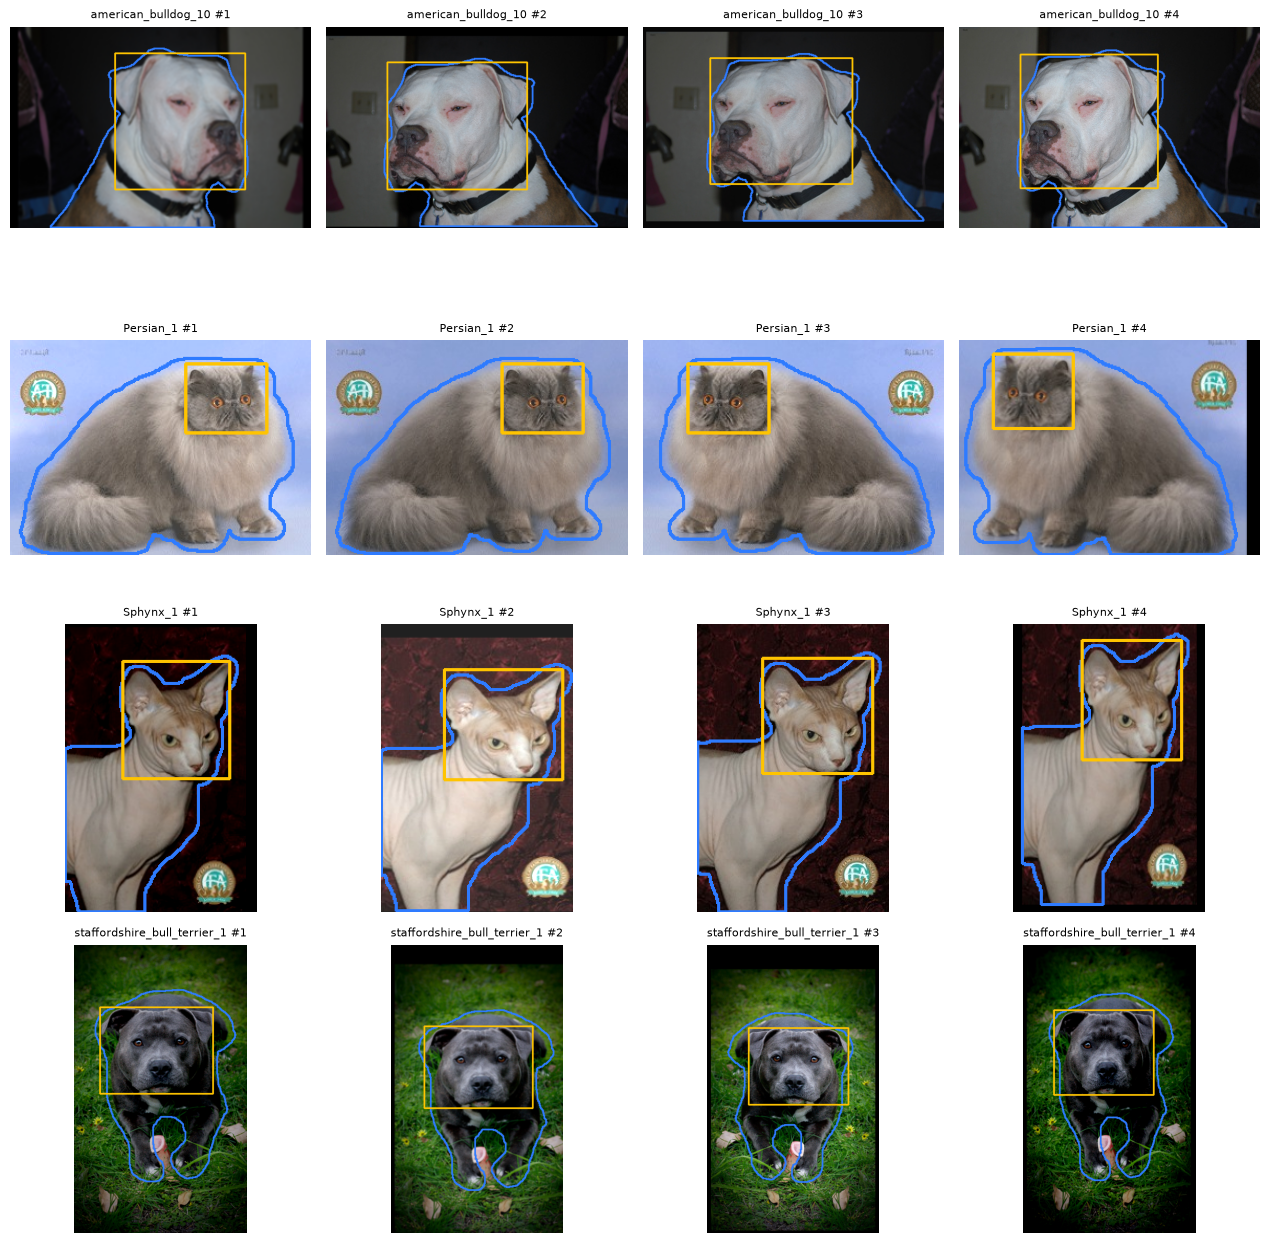

In [22]:
def apply(tf, filename):
    rgb, tri, xml = load_rgb(filename), load_trimap(filename), read_xml(filename)
    # XML: 1-based inclusive. Albumentations: zero-based pixel edges.
    boxes = [[x0-1, y0-1, x1, y1] for x0, y0, x1, y1 in image_boxes(xml)]
    r = tf(image=rgb, mask=animal_mask(tri), bboxes=boxes, labels=[0] * len(boxes))
    assert r["image"].shape[:2] == r["mask"].shape
    assert set(np.unique(r["mask"])) <= {0, 1}
    return r["image"], r["mask"], r["bboxes"]


demo = labels[(labels["split"] == "train") & labels["filename"].isin(audit.loc[audit["has_xml"] & (audit["trimap_empty"] != True), "filename"])]
demo = demo.groupby("class_id").head(1)["filename"].tolist()[:4]
assert len(demo) == 4
for fn in demo:
    img, _, boxes = apply(eval_transform, fn)
    assert max(img.shape[:2]) == 640 and len(boxes) == len(image_boxes(read_xml(fn)))
panels, titles = [], []
for fn in demo:
    for k in range(4):
        img, m, bb = apply(train_transform, fn)
        panels.append(draw_boxes(draw_mask_contour(img, m), bb)); titles.append(f"{Path(fn).stem} #{k + 1}")
show_grid(panels, titles, ncols=4, path=RESULTS / "aug_audit.png", size=3.2)

## 2.5 Аугментация, которая ломает

Выберите одно преобразование или настройку, которая портит разметку или меняет правильный ответ: сильный кроп, поворот на большой угол, сдвиг оттенка для вашей трудной пары пород или своё. Впишите его в `BAD_TRANSFORM`: готовая ячейка нарисует 4 примера в `results/aug_bad.png`.

Затем посчитайте на всех фото с рамкой, в какой доле случаев разметка испорчена. Для геометрии есть две готовые функции:

- `crop_visible(box, W, H, rng, scale, ratio)` — доля головы, которая попала в случайный кроп с параметрами `RandomResizedCrop`;
- `rotated_box_iou(box, angle)` — IoU рамки, описанной вокруг повёрнутой рамки, с самой рамкой.

Критерий выберите сами и запишите его в выводы: голова целиком вне кадра, видно меньше половины головы, IoU меньше 0,7 или свой.

In [23]:
def crop_bounds(w, h):
    # Те же границы, которые использует A.CenterCrop.
    cw, ch = max(1, round(w * 0.35)), max(1, round(h * 0.35))
    x, y = (w - cw) // 2, (h - ch) // 2
    return x, y, x + cw, y + ch


def crop_visible(box, w, h):
    x, y, x_end, y_end = crop_bounds(w, h)
    bx, by, bw, bh = voc_to_coco(box)
    iw = max(0, min(bx+bw, x_end) - max(bx, x))
    ih = max(0, min(by+bh, y_end) - max(by, y))
    return iw * ih / (bw * bh)

Центральный кроп 35% × 35%: 404 фото с рамками. Хотя бы одна голова сохранилась меньше чем наполовину на 331 фото (81.93%). Полностью вне кадра хотя бы одна голова на 16 фото (3.96%).


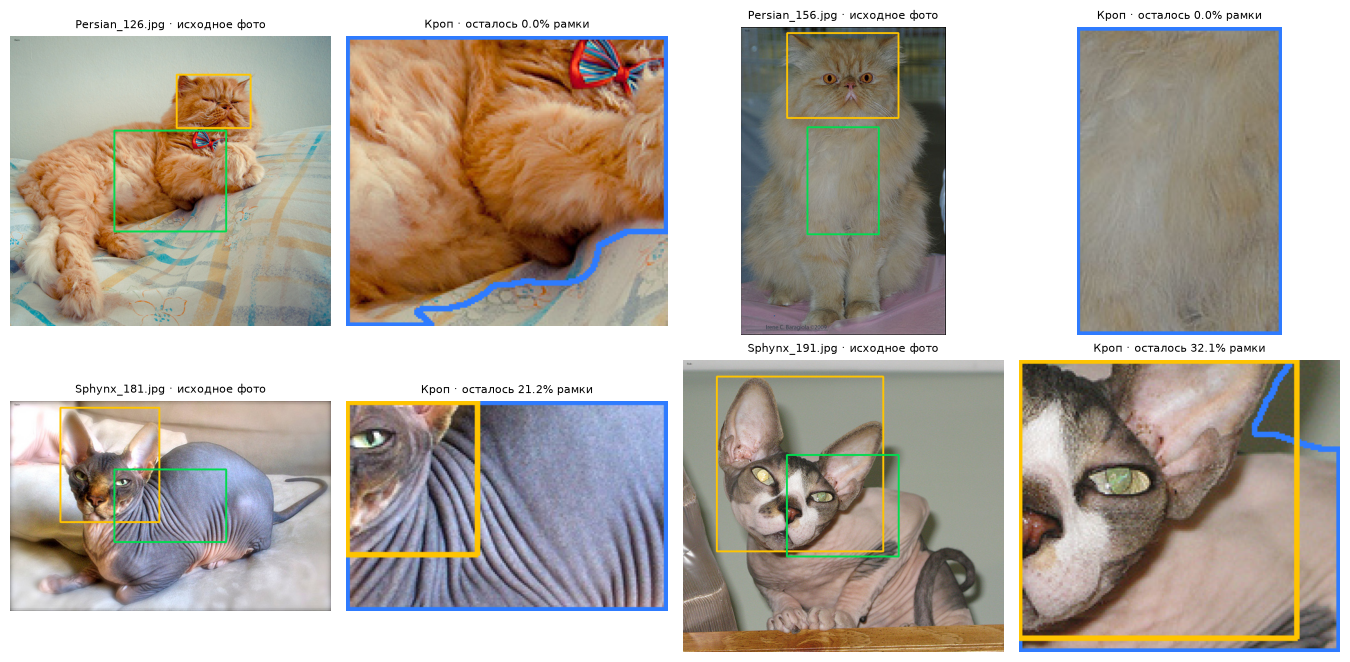

In [24]:
visibility = pd.DataFrame([
    (fn, crop_visible(box, w, h)) for fn, w, h, box in box_records
], columns=["filename", "visible"])
bad_by_photo = visibility.groupby("filename")["visible"].min()
bad_fraction = float(bad_by_photo.lt(0.5).mean())
lost_fraction = float(bad_by_photo.eq(0).mean())
print(f"Центральный кроп 35% × 35%: {len(bad_by_photo)} фото с рамками. "
      f"Хотя бы одна голова сохранилась меньше чем наполовину на {bad_by_photo.lt(0.5).sum()} "
      f"фото ({bad_fraction:.2%}). Полностью вне кадра хотя бы одна голова на "
      f"{bad_by_photo.eq(0).sum()} фото ({lost_fraction:.2%}).")

panels, titles = [], []
zero = bad_by_photo[bad_by_photo.eq(0)].index[:2]
partial = bad_by_photo[bad_by_photo.between(0, 0.5, inclusive="neither")]
demo_bad = [*zero, *partial.sort_values().iloc[[len(partial)//3, 2*len(partial)//3]].index]
for fn in demo_bad:
    rgb = load_rgb(fn)
    h, w = rgb.shape[:2]
    x, y, x_end, y_end = crop_bounds(w, h)
    bad_transform = A.Compose([A.CenterCrop(height=y_end-y, width=x_end-x, p=1)], bbox_params=BBOX)
    img, mask, boxes = apply(bad_transform, fn)
    original_boxes = [[v-1 for v in b] for b in image_boxes(read_xml(fn))]
    original = draw_boxes(draw_boxes(rgb, original_boxes), [[x, y, x_end-1, y_end-1]], (0, 220, 80))
    panels.extend([original, draw_boxes(draw_mask_contour(img, mask), boxes)])
    titles.extend([fn + " · исходное фото", f"Кроп · осталось {bad_by_photo[fn]:.1%} рамки"])
show_grid(panels, titles, ncols=4, path=RESULTS / "aug_bad.png", size=3.4)

## 3. Проверка результатов и выгрузка

In [25]:
print(f"вариант {VARIANT} | BORDER_AS = {BORDER_AS} | отмечено пар: {sum(v != '' for v in dup['verdict'])} | "
      f"групп из 2+ фото: {len(multi)} | split: {labels['split'].value_counts().to_dict()}")
expected = {"audit.csv", "coco.json", "yolo", "format_check.png", "dup_pairs.csv", "dup_candidates.png",
            "distribution.png", "split.csv", "split_summary.csv", "aug_audit.png", "aug_bad.png"}
missing = sorted(expected - {p.name for p in RESULTS.iterdir()})
print("не хватает:", ", ".join(missing) if missing else "ничего, все 11 результатов на месте")
assert not missing, missing
assert len(coco["images"]) == len(labels) == len(audit)
assert len(list((YOLO_DIR / "labels").glob("*.txt"))) == audit["has_xml"].sum()
assert len([*RESULTS.iterdir()]) == 11


вариант 9 | BORDER_AS = animal | отмечено пар: 30 | групп из 2+ фото: 12 | split: {'train': 571, 'test': 113, 'val': 113}
не хватает: ничего, все 11 результатов на месте


In [26]:
if ENV != "local":
    import shutil
    print("Архив результатов:", shutil.make_archive("results", "zip", RESULTS))
print("все 11 результатов на месте")

все 11 результатов на месте
